# 여백 크롭 규칙 검증

학습 전에 여백 크롭 규칙이 맞는지 확인한다. 학습은 하지 않는다. 다음 세 가지를 확인한다.

1. 임계값 T에 따른 크롭 영역의 안정성 (train과 test 전체)
2. test 이미지 가장자리의 밝기 분포 (크롭이 test에 실제로 무엇을 하는지)
3. 크롭 전후 프레이밍 통계 (train과 test가 더 비슷해지는지)

임계값 T는 train에서만 고른다. test에는 같은 규칙을 적용하고 라벨은 사용하지 않는다.

## 1. 환경 설정

In [1]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

from matplotlib import font_manager
_installed = {f.name for f in font_manager.fontManager.ttflist}
for _font in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR"]:
    if _font in _installed:
        plt.rcParams["font.family"] = _font
        break
plt.rcParams["axes.unicode_minus"] = False

D = next(p for p in ["../../data"] if os.path.exists(os.path.join(p, "train.csv")))
os.makedirs("../../analysis", exist_ok=True)
tr = pd.read_csv(os.path.join(D, "train.csv"))
te = pd.read_csv(os.path.join(D, "test.csv"))
print("train:", len(tr), "| test:", len(te), "| 데이터 폴더:", D)

train: 5216 | test: 624 | 데이터 폴더: ../open (1)


## 2. 크롭 규칙 정의

크롭 영역은 밝기가 T보다 큰 픽셀들의 바운딩 박스다. 이 규칙은 이미지마다 따로 적용되므로 다른 이미지의 정보를 쓰지 않는다. T는 train에서 정한 값을 test에도 그대로 쓴다.

In [2]:
def load_gray(folder, f):
    return np.asarray(Image.open(os.path.join(D, folder, f)).convert("L"))

def content_bbox(a, T):
    m = a > T
    r = np.where(m.any(1))[0]; c = np.where(m.any(0))[0]
    if len(r) == 0:
        return 0, a.shape[0] - 1, 0, a.shape[1] - 1
    return r.min(), r.max(), c.min(), c.max()

## 3. 임계값 민감도 (train 전체, test 전체)

임계값을 0~30으로 바꿔 가며 각 이미지의 크롭 영역 비율을 잰다. 각 이미지에서 T=0 때 영역과의 차이를 구해 중앙값을 본다. 차이가 작은 구간은 T를 골라도 결과가 거의 같다는 뜻이다. 이 값이 임계값을 고른 근거가 된다.

 T  train_영역비_중앙값  train_T0대비_변화_중앙값  test_영역비_중앙값  test_T0대비_변화_중앙값
 0         0.7188                0.0           1.0               0.0
 2         0.7188                0.0           1.0               0.0
 5         0.7188                0.0           1.0               0.0
 8         0.7188                0.0           1.0               0.0
10         0.7185                0.0           1.0               0.0
15         0.7155                0.0           1.0               0.0
20         0.7143                0.0           1.0               0.0
30         0.7136                0.0           1.0               0.0


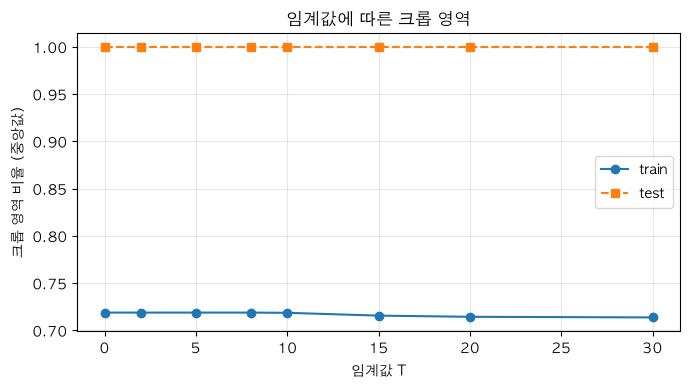

In [3]:
Ts = [0, 2, 5, 8, 10, 15, 20, 30]

def sweep(folder, files):
    rows = []
    for f in files:
        a = load_gray(folder, f); H, W = a.shape
        rec = {}
        for t in Ts:
            r0, r1, c0, c1 = content_bbox(a, t)
            rec[t] = (r1 - r0 + 1) * (c1 - c0 + 1) / (H * W)
        rows.append(rec)
    return pd.DataFrame(rows)

sw_tr = sweep("train", tr.file_name)
sw_te = sweep("test", te.file_name)

summary = pd.DataFrame({
    "T": Ts,
    "train_영역비_중앙값": sw_tr[Ts].median().values.round(4),
    "train_T0대비_변화_중앙값": [round((sw_tr[t] - sw_tr[0]).abs().median(), 4) for t in Ts],
    "test_영역비_중앙값": sw_te[Ts].median().values.round(4),
    "test_T0대비_변화_중앙값": [round((sw_te[t] - sw_te[0]).abs().median(), 4) for t in Ts],
})
print(summary.to_string(index=False))
summary.to_csv("../../analysis/crop_threshold_sweep.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Ts, sw_tr[Ts].median().values, "o-", label="train")
ax.plot(Ts, sw_te[Ts].median().values, "s--", label="test")
ax.set_xlabel("임계값 T"); ax.set_ylabel("크롭 영역 비율 (중앙값)"); ax.set_title("임계값에 따른 크롭 영역")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig("../../analysis/crop_threshold_sweep.png", dpi=120); plt.show()

## 4. test 가장자리 밝기 확인

위 결과에서 test는 T를 올려도 영역이 전체 이미지로 나왔다. 가장자리에 밝은 픽셀이 있는지 확인한다. 가장자리 각 줄에서 T=10보다 밝은 픽셀의 비율을 본다. 비율이 높으면 그 가장자리에는 잘라낼 여백이 없다는 뜻이다.

In [4]:
T_USE = 10

def edge_share(folder, files, T):
    rows = []
    for f in files:
        a = load_gray(folder, f)
        rows.append({"top": (a[0] > T).mean(), "bottom": (a[-1] > T).mean(),
                     "left": (a[:, 0] > T).mean(), "right": (a[:, -1] > T).mean()})
    return pd.DataFrame(rows)

edge_tr = edge_share("train", tr.file_name, T_USE)
edge_te = edge_share("test", te.file_name, T_USE)
edge_summary = pd.DataFrame({
    "train_중앙값": edge_tr.median().round(3),
    "test_중앙값": edge_te.median().round(3),
    "test_줄에_밝은픽셀_있는_비율": (edge_te > 0.01).mean().round(3),
})
print(edge_summary)

        train_중앙값  test_중앙값  test_줄에_밝은픽셀_있는_비율
top         0.000     0.976               0.998
bottom      0.000     0.925               0.998
left        0.174     0.195               0.681
right       0.179     0.308               0.772


## 5. 크롭 전후 프레이밍 통계

크롭이 train과 test의 프레이밍 차이를 줄이는지 확인한다. 두 가지 값을 비교한다.

* **비여백 비율**: 영역 안에서 밝기가 T보다 큰 픽셀의 비율. 값이 비슷하면 이미지 안의 내용 밀도가 비슷하다는 뜻이다.
* **종횡비(가로/세로)**: 영역의 모양. 값이 비슷하면 크롭 후 같은 비율로 맞출 수 있다는 뜻이다.

train은 크롭 전(원본 224 letterbox)과 크롭 후를 비교하고, test는 원본 그대로 비교한다.

In [5]:
def frame_stats(a, T):
    r0, r1, c0, c1 = content_bbox(a, T)
    H, W = a.shape
    crop = a[r0:r1 + 1, c0:c1 + 1]
    return {"내용비율_크롭전": (a > T).mean(),
            "내용비율_크롭후": (crop > T).mean(),
            "종횡비_크롭후": crop.shape[1] / crop.shape[0]}

rows_tr = [frame_stats(load_gray("train", f), T_USE) for f in tr.file_name]
rows_te = [frame_stats(load_gray("test", f), T_USE) for f in te.file_name]
df_tr = pd.DataFrame(rows_tr); df_te = pd.DataFrame(rows_te)

stats_table = pd.DataFrame({
    "train 크롭 전": [df_tr["내용비율_크롭전"].median(), df_tr["종횡비_크롭후"].median() * 0 + 1],
    "train 크롭 후": [df_tr["내용비율_크롭후"].median(), df_tr["종횡비_크롭후"].median()],
    "test (크롭 적용)": [df_te["내용비율_크롭후"].median(), df_te["종횡비_크롭후"].median()],
}, index=["내용비율 (중앙값)", "종횡비 (중앙값, 가로/세로)"]).round(3)
print(stats_table)
stats_table.to_csv("../../analysis/crop_framing_stats.csv")
print("\ntrain 크롭 후 종횡비 범위:", df_tr["종횡비_크롭후"].quantile([0.05, 0.95]).round(3).tolist(),
      "| test 종횡비 범위:", df_te["종횡비_크롭후"].quantile([0.05, 0.95]).round(3).tolist())

                  train 크롭 전  train 크롭 후  test (크롭 적용)
내용비율 (중앙값)             0.663       0.927         0.953
종횡비 (중앙값, 가로/세로)       1.000       1.372         1.442

train 크롭 후 종횡비 범위: [1.068, 1.808] | test 종횡비 범위: [1.107, 1.855]


## 6. 시각 확인

크롭 경계를 실제 이미지에 그려서 여백만 잘려 나가는지 확인한다. 위쪽은 원본과 경계(빨간 사각형), 아래쪽은 크롭 결과다. train 4장과 test 4장을 보여준다.

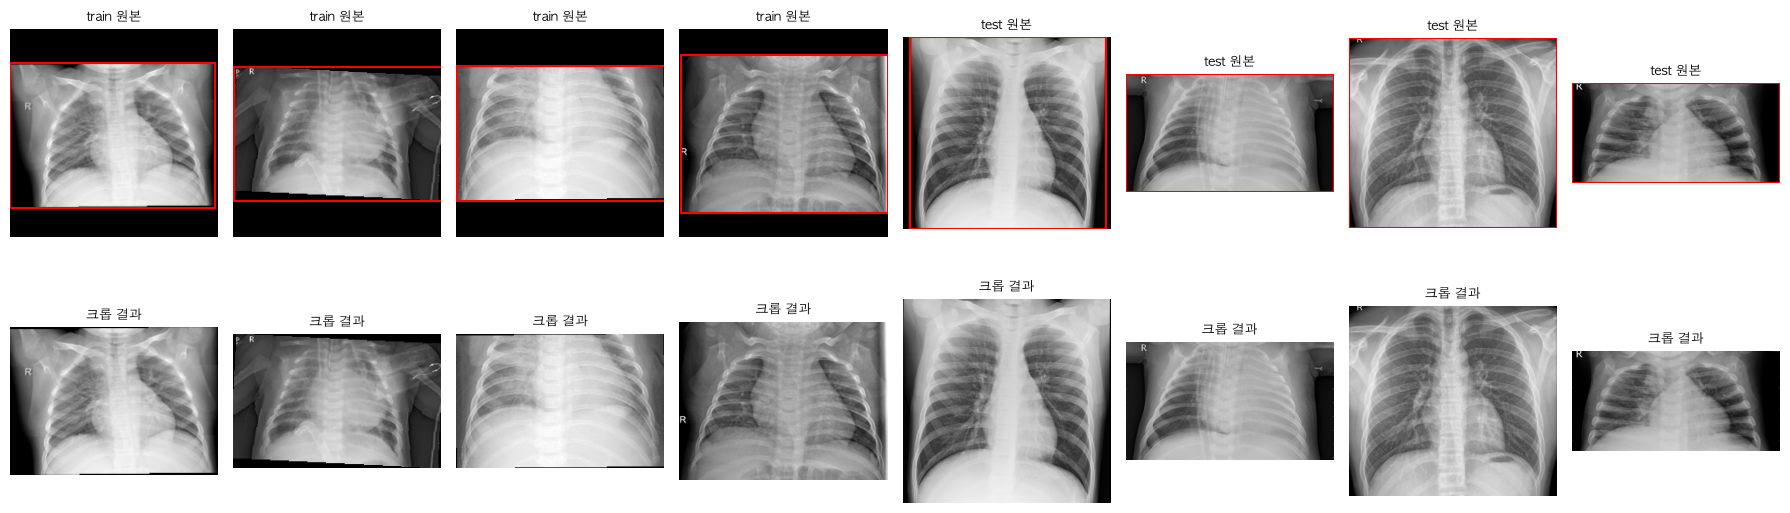

In [6]:
sample_tr = tr.file_name.sample(4, random_state=1).tolist()
sample_te = te.file_name.sample(4, random_state=1).tolist()
fig, axes = plt.subplots(2, 8, figsize=(18, 6))
for k, (folder, f) in enumerate([("train", x) for x in sample_tr] + [("test", x) for x in sample_te]):
    a = load_gray(folder, f)
    r0, r1, c0, c1 = content_bbox(a, T_USE)
    ax = axes[0, k]; ax.imshow(a, cmap="gray"); ax.axis("off")
    ax.add_patch(Rectangle((c0, r0), c1 - c0 + 1, r1 - r0 + 1, fill=False, edgecolor="red", lw=1.5))
    ax.set_title(f"{folder} 원본", fontsize=9)
    ax = axes[1, k]; ax.imshow(a[r0:r1 + 1, c0:c1 + 1], cmap="gray"); ax.axis("off")
    ax.set_title("크롭 결과", fontsize=9)
plt.tight_layout(); plt.savefig("../../analysis/crop_visual_check.png", dpi=110); plt.show()

## 7. 결과 해석

위 결과로 확인할 내용은 다음과 같다. 셀 실행 후 채운다.

* 임계값 T: 안정 구간의 범위와 선택한 T 값
* test 가장자리: 잘라낼 여백이 있는지 없는지
* 프레이밍: 크롭 후 train과 test의 내용 비율과 종횡비 차이
* 시각 확인: 크롭 경계가 여백에만 걸렸는지